# Customer Churn Prediction — Preprocessing & ML


## 1- Imports and reproducibility

Import the libraries used for data preparation, model training and evaluation

In [ ]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.api.types import is_object_dtype, is_string_dtype

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
DATA_PATH = "Telco-Customer-Churn.csv"
ARTIFACT_PATH = "churn_model.pkl"
METADATA_PATH = "churn_model_metadata.json"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")



## 2- Load and validate the raw dataset

In [3]:
# Load the dataset
data_file = Path(DATA_PATH)
if not data_file.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH!r}.")

df_raw = pd.read_csv(data_file)
print(Path.cwd())


e:\depi\final project


In [4]:
# Display basic information about the dataset

print("Duplicate rows:", df_raw.duplicated().sum())
print("Target values:", sorted(df_raw["Churn"].astype(str).unique()))
print("\nData Information:\n")

df_raw.info()


Duplicate rows: 0
Target values: ['No', 'Yes']

Data Information:

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null  

In [5]:
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3- Data preprocessing and quality checks

The TotalCharges column is stored as text, so it must be converted to a numeric type with blank entries turned into missing values. Missing-value imputation is fitted later inside the preprocessing pipeline using the training data only to avoid data leakage.

In [6]:
df = df_raw.copy()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(),errors="coerce")


df = df[df["Churn"].isin(["Yes", "No"])].copy()

print("dataset shape:", df.shape)

# check for missing values and zero-tenure customers
print("missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

print("Zero-tenure customers:", (df["tenure"] == 0).sum())
print("\nTarget distribution:")

# create a summary DataFrame for churn distribution
churn_summary = pd.DataFrame({
    "customers": df["Churn"].value_counts(),
    "percentage": (df["Churn"].value_counts(normalize=True) * 100).round(2)})

display(churn_summary)

# check the data type of the TotalCharges column
print("totalcharge column data type is:", df["TotalCharges"].dtype)


dataset shape: (7043, 21)
missing values by column:


,missing_count
TotalCharges,11
customerID,0
DeviceProtection,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0


Zero-tenure customers: 11

Target distribution:


,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


totalcharge column data type is: float64


Only the TotalCharges column contains missing values (11 rows, corresponding to the 11 zero-tenure customers). The cleaned dataset has 7,043 rows and 21 columns, with an imbalanced target distribution of 73.46% non-churners (5,174 customers) and 26.54% churners (1,869 customers).

In [7]:
# export the cleaned dataset for team analysis.
output_path = Path("Telco_Customer_Churn_Preprocessed.csv")

df.to_csv(output_path, index=False)

print(f"Dataset exported successfully: {output_path.resolve()}")


Dataset exported successfully: E:\depi\final project\Telco_Customer_Churn_Preprocessed.csv


## 4- Define features and split the data

The customerID column is only an identifier, so it is excluded from the predictive features. The dataset is split using stratified sampling into a training set (60%, 4,225 rows), a validation set (10%, 704 rows), an independent feature-importance holdout (10%, 705 rows), and a test set (20%, 1,409 rows) kept until final evaluation.

In [8]:
# Split the dataset into training, validation, and test sets

X = df.drop(columns=["Churn", "customerID"], errors="ignore").copy()
y = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# split the remaining 80% into 60% training, 10% validation, and 10% feature-importance data.
X_train, X_holdout, y_train, y_holdout = train_test_split(X_train_full, y_train_full, test_size=0.25,stratify=y_train_full, random_state=RANDOM_STATE)

X_valid, X_importance, y_valid, y_importance = train_test_split(X_holdout, y_holdout, test_size=0.50,stratify=y_holdout, random_state=RANDOM_STATE)

print("training set:", X_train.shape)
print("validation set:", X_valid.shape)
print("feature-importance holdout:", X_importance.shape)
print("test set:", X_test.shape)


training set: (4225, 19)
validation set: (704, 19)
feature-importance holdout: (705, 19)
test set: (1409, 19)


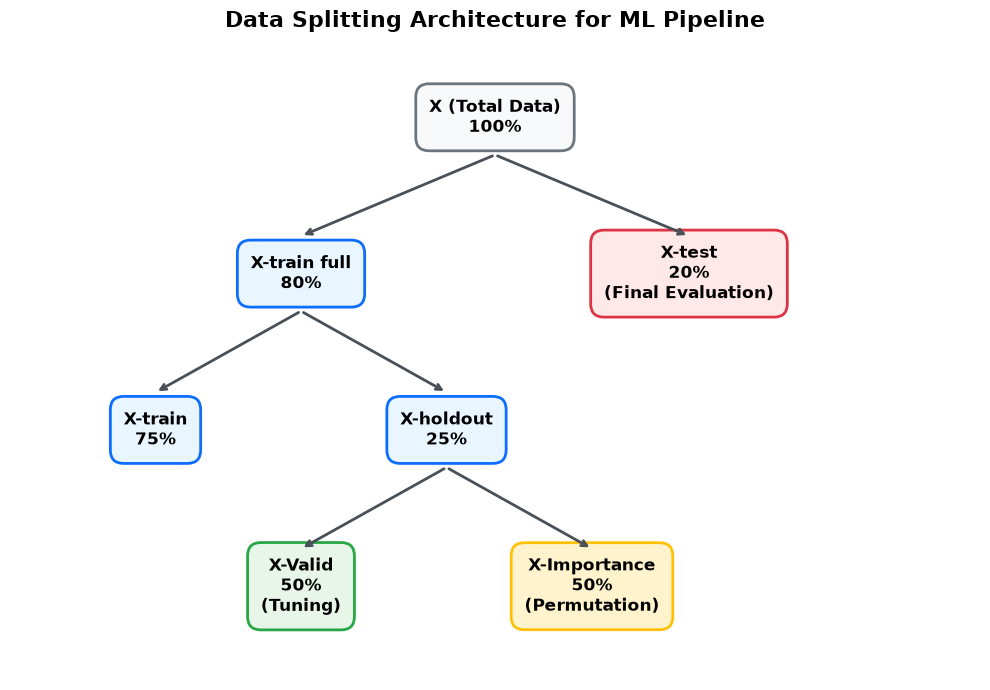

In [ ]:
# visulize data splitting hierarchy

# Set figure size and hide axes
fig, ax = plt.subplots(figsize=(10, 7))
ax.axis('off')

# Node and edge styling
def draw_node(text, x, y, bg_color="#e9f5ff", border_color="#0d6efd"):
    ax.text(x, y, text, ha="center", va="center", size=12, fontweight='bold', 
            bbox=dict(boxstyle="round,pad=0.8", fc=bg_color, ec=border_color, lw=2))

def draw_edge(x1, y1, x2, y2):
    # Draw an arrow between two points
    ax.annotate("", xy=(x2, y2+0.06), xytext=(x1, y1-0.06), 
                arrowprops=dict(arrowstyle="->", color="#495057", lw=2))

# 1. Draw nodes (boxes) and position them geometrically based on the architecture
# Level 1: Full Dataset
draw_node("X (Total Data)\n100%", 0.5, 0.9, bg_color="#f8f9fa", border_color="#6c757d")

# Level 2: First Split (Train/Test)
draw_node("X-train full\n80%", 0.3, 0.65)
draw_node("X-test\n20%\n(Final Evaluation)", 0.7, 0.65, bg_color="#ffe8e8", border_color="#dc3545") 

# Level 3: Second Split (Train/Holdout)
draw_node("X-train\n75%", 0.15, 0.4)
draw_node("X-holdout\n25%", 0.45, 0.4)

# Level 4: Third Split (Validation/Importance)
draw_node("X-Valid\n50%\n(Tuning)", 0.3, 0.15, bg_color="#e8f5e9", border_color="#28a745") 
draw_node("X-Importance\n50%\n(Permutation)", 0.6, 0.15, bg_color="#fff3cd", border_color="#ffc107") 

# 2. Draw connections (arrows)
# Connections from Level 1 to 2
draw_edge(0.5, 0.9, 0.3, 0.65)
draw_edge(0.5, 0.9, 0.7, 0.65)

# Connections from Level 2 to 3
draw_edge(0.3, 0.65, 0.15, 0.4)
draw_edge(0.3, 0.65, 0.45, 0.4)

# Connections from Level 3 to 4
draw_edge(0.45, 0.4, 0.3, 0.15)
draw_edge(0.45, 0.4, 0.6, 0.15)

# Add main title and adjust layout
plt.title("Data Splitting Architecture for ML Pipeline", fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()

# Save the figure as a high-resolution image for the final report
plt.savefig("data_splitting_hierarchy.png", dpi=300, bbox_inches='tight')

# Display the plot in the Jupyter Notebook
plt.show()


## 5- Build a preprocessing pipeline

For numeric columns, median imputation followed by standardization is applied. For categorical columns, most-frequent imputation followed by one-hot encoding is applied. Combining these steps inside a ColumnTransformer ensures all preprocessing is fitted only on the training data.

In [10]:
# identify categorical columns across different data types for flexible preprocessing.
def get_categorical_columns(frame):
    return [
        col for col in frame.columns
        if is_object_dtype(frame[col]) or is_string_dtype(frame[col])
        or isinstance(frame[col].dtype, pd.CategoricalDtype)]

# Separate numerical and categorical features.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = get_categorical_columns(X_train)

# display detected features for validation.
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# impute missing numerical values and standardize numerical features.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

# impute missing categorical values and one-hot encode categories
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

# combine both transformers into a single preprocessor
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)])

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 6- Create a baseline model

A DummyClassifier that always predicts the majority class is used as a simple reference point. Because most customers in the dataset did not churn, this baseline achieves relatively high Accuracy while getting zero Recall.

In [11]:

# create a baseline model using the most frequent class strategy
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_valid)

# evaluate performance of the baseline model on the validation set
baseline_results = pd.DataFrame([{
    "Model": "Most-frequent baseline",
    "Accuracy": accuracy_score(y_valid, baseline_pred),
    "Precision": precision_score(y_valid, baseline_pred, zero_division=0),
    "Recall": recall_score(y_valid, baseline_pred, zero_division=0),
    "F1": f1_score(y_valid, baseline_pred, zero_division=0)}]).set_index("Model")

display(baseline_results.round(3))

,Accuracy,Precision,Recall,F1
Model,,,,
Most-frequent baseline,0.73,0.00,0.00,0.00


The baseline reaches 73.4% Accuracy simply by predicting no churn for every customer, resulting in zero Recall, Precision, and F1-score. Because it fails to identify any churners, Recall is prioritized as the primary metric rather than relying on Accuracy alone.

## 7- Choose the candidate models before training

Five models from different modeling families are evaluated using 5-fold stratified cross-validation:

- Logistic Regression: an interpretable linear baseline with balanced class weights.
- Random Forest: an ensemble of decision trees that can capture nonlinear patterns.
- XGBoost: a gradient-boosting model that builds trees sequentially to correct earlier errors.
- LightGBM: a histogram-based gradient-boosting model designed for high efficiency on tabular data.
- CatBoost: a gradient-boosting model based on symmetric trees that handles complex feature interactions and resists overfitting.

Recall is the primary selection metric because the project focuses on identifying customers who actually churn. Precision, F1-score, PR-AUC, and ROC-AUC are also considered so that higher Recall is evaluated alongside false alarms and overall discrimination.

In [ ]:
%%time

# combine preprocessing and model into a single pipeline.
def make_pipeline(estimator):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)])

# initialize the candidate models with their default settings
logistic_model = make_pipeline(LogisticRegression(
    max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))

rf_pipeline = make_pipeline(RandomForestClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1))


xgb_pipeline = make_pipeline(
    XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,
        tree_method="hist"))

lgbm_pipeline = make_pipeline(
    LGBMClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=-1))

catboost_pipeline = make_pipeline(
    CatBoostClassifier(
        auto_class_weights="Balanced",
        random_state=RANDOM_STATE,
        thread_count=1,
        allow_writing_files=False,
        verbose=0))




# define stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# chosse the evaluation metrics for model comparison.
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"}

#evaluate each model across the cross-validation folds.
def summarize_cv(model, name, X_data, y_data):
    scores = cross_validate(
        model, X_data, y_data, cv=cv, scoring=scoring,
        n_jobs=-1, error_score="raise")
    return {
        "Model": name,
        "Recall mean": scores["test_recall"].mean(),
        "Recall std": scores["test_recall"].std(),
        "F1 mean": scores["test_f1"].mean(),
        "PR-AUC mean": scores["test_pr_auc"].mean(),
        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "precision_score": scores["test_precision"].mean()}

#collect the candidate models for comparison.
initial_candidates = [
    (logistic_model, "Logistic Regression"),
    (rf_pipeline, "Random Forest (default)"),
    (xgb_pipeline, "XGBoost (default)"),
    (lgbm_pipeline, "LightGBM (default)"),
    (catboost_pipeline, "CatBoost (default)")]

#run cross-validation and collect the results.
initial_cv = pd.DataFrame([summarize_cv(model, name, X_train, y_train)
    for model, name in initial_candidates]).set_index("Model")

# sort models by Recall as primary metric and f1 as scecondry metric in descending order
display(initial_cv.sort_values(["Recall mean", "F1 mean"], ascending=False).round(2))

,Recall mean,Recall std,F1 mean,PR-AUC mean,ROC-AUC mean,precision_score
Model,,,,,,
Logistic Regression,0.81,0.03,0.63,0.67,0.85,0.52
CatBoost (default),0.73,0.04,0.63,0.66,0.84,0.55
LightGBM (default),0.71,0.03,0.61,0.65,0.83,0.54
Random Forest (default),0.64,0.04,0.60,0.61,0.83,0.56
XGBoost (default),0.52,0.03,0.56,0.62,0.82,0.61


CPU times: total: 1.47 s
Wall time: 1min 2s


In the initial 5-fold cross-validation comparison, Logistic Regression achieved the highest Recall (0.81), PR-AUC (0.67), and ROC-AUC (0.85), followed by CatBoost (Recall 0.73, F1 0.63) and LightGBM (Recall 0.71, F1 0.61). Random Forest (Recall 0.64) and default XGBoost without class weighting (Recall 0.52) had lower initial Recall, showing the need for hyperparameter tuning.

## 8- Hyperparameter tuning

All five candidate models are tuned using 5-fold stratified cross-validation on the training set with F1-score as the optimization metric to balance Recall and Precision. Logistic Regression is tuned with GridSearchCV, while the tree-based and gradient-boosting models (Random Forest, XGBoost, LightGBM, and CatBoost) are tuned with RandomizedSearchCV over 100 iterations. The search spaces are bounded to keep runtime reasonable, and all metrics are compared during validation and final testing.

In [13]:
from sklearn.model_selection import GridSearchCV

lr_params = {
    "model__C": [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
    "model__l1_ratio": [0, 1],
    "model__solver": ["liblinear"],
    "model__class_weight": ["balanced", {0: 1, 1: 2}, {0: 1, 1: 3}]}

lr_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=lr_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise")

lr_search.fit(X_train, y_train)

print("Logistic Regression best CV F1:", round(lr_search.best_score_, 3))
display(pd.Series(lr_search.best_params_, name="value").to_frame())


Logistic Regression best CV F1: 0.634


,value
model__C,0.01
model__class_weight,"{0: 1, 1: 2}"
model__l1_ratio,0
model__solver,liblinear


In [14]:
%%time

# set the number of iterations
N_ITER = 100

# define the hyperparameter search spaces for tree and boosting ensemble models.
rf_params = {
    "model__n_estimators": [300, 500, 700, 900],
    "model__max_depth": [None, 6, 10, 14, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2", 0.5, 0.8],
    "model__class_weight": ["balanced", "balanced_subsample"]}


xgb_params = {
    "model__n_estimators": [150, 250, 400, 600],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__min_child_weight": [1, 3, 5, 8],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__reg_alpha": [0, 0.01, 0.1, 1.0],
    "model__reg_lambda": [1, 3, 5, 10],
    "model__scale_pos_weight": [1.0, 2.0, 2.8]}

lgbm_params = {
    "model__n_estimators": [150, 250, 400, 600],
    "model__max_depth": [-1, 3, 5, 7, 10],
    "model__num_leaves": [15, 31, 50, 70],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__min_child_samples": [10, 20, 40, 60],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__subsample_freq": [1],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__reg_alpha": [0, 0.01, 0.1, 1.0],
    "model__reg_lambda": [1, 3, 5, 10],
    "model__class_weight": ["balanced", None]}

catboost_params = {
    "model__iterations": [200, 400, 600, 800],
    "model__depth": [4, 5, 6, 7, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__l2_leaf_reg": [1, 3, 5, 10],
    "model__bootstrap_type": ["Bernoulli"],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__auto_class_weights": ["Balanced", "SqrtBalanced"]}

# create randomized search for tree and boosting ensemble models.
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline, param_distributions=rf_params,
    n_iter=N_ITER, scoring="f1", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    verbose=1, error_score="raise")


xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline, param_distributions=xgb_params,
    n_iter=N_ITER, scoring="f1", cv=cv,
    random_state=RANDOM_STATE + 2, n_jobs=-1, refit=True,
    verbose=1, error_score="raise")

lgbm_search = RandomizedSearchCV(
    estimator=lgbm_pipeline, param_distributions=lgbm_params,
    n_iter=N_ITER, scoring="f1", cv=cv,
    random_state=RANDOM_STATE + 3, n_jobs=-1, refit=True,
    verbose=1, error_score="raise")

catboost_search = RandomizedSearchCV(
    estimator=catboost_pipeline, param_distributions=catboost_params,
    n_iter=N_ITER, scoring="f1", cv=cv,
    random_state=RANDOM_STATE + 4, n_jobs=-1, refit=True,
    verbose=1, error_score="raise")

# start tuning hyperparameters
rf_search.fit(X_train, y_train)
xgb_search.fit(X_train, y_train)
lgbm_search.fit(X_train, y_train)
catboost_search.fit(X_train, y_train)

# display the best F1 score and parameters.
print("Random Forest best CV F1:", round(rf_search.best_score_, 3))
display(pd.Series(rf_search.best_params_, name="value").to_frame())


print("XGBoost best CV F1:", round(xgb_search.best_score_, 3))
display(pd.Series(xgb_search.best_params_, name="value").to_frame())

print("LightGBM best CV F1:", round(lgbm_search.best_score_, 3))
display(pd.Series(lgbm_search.best_params_, name="value").to_frame())

print("CatBoost best CV F1:", round(catboost_search.best_score_, 3))
display(pd.Series(catboost_search.best_params_, name="value").to_frame())


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Random Forest best CV F1: 0.638


,value
model__n_estimators,900
model__min_samples_split,15
model__min_samples_leaf,6
model__max_features,sqrt
model__max_depth,10
model__class_weight,balanced_subsample


XGBoost best CV F1: 0.638


,value
model__subsample,0.70
model__scale_pos_weight,2.00
model__reg_lambda,3.00
model__reg_alpha,0.01
model__n_estimators,600.00
model__min_child_weight,5.00
model__max_depth,2.00
model__learning_rate,0.01
model__colsample_bytree,1.00


LightGBM best CV F1: 0.633


,value
model__subsample_freq,1
model__subsample,1.00
model__reg_lambda,10
model__reg_alpha,0
model__num_leaves,31
model__n_estimators,150
model__min_child_samples,60
model__max_depth,3
model__learning_rate,0.05
model__colsample_bytree,0.85


CatBoost best CV F1: 0.637


,value
model__subsample,0.70
model__learning_rate,0.05
model__l2_leaf_reg,10
model__iterations,200
model__depth,4
model__bootstrap_type,Bernoulli
model__auto_class_weights,Balanced


CPU times: total: 56.8 s
Wall time: 45min 57s


After hyperparameter tuning on F1-score, Random Forest and XGBoost tied for the highest 5-fold cross-validation F1 (0.638), closely followed by CatBoost (0.637), Logistic Regression (0.634), and LightGBM (0.633).


## 9- Compare candidates on the validation set

All five tuned candidates are evaluated on the same validation set at the default probability threshold of 0.50. Recall is the primary comparison metric, with F1-score, PR-AUC, and ROC-AUC providing additional context.

In [15]:

# Store the trained candidate models for validation.
candidate_models = {
    "Tuned Logistic Regression":lr_search.best_estimator_,
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned XGBoost" : xgb_search.best_estimator_,
    "Tuned LightGBM": lgbm_search.best_estimator_,
    "Tuned CatBoost": catboost_search.best_estimator_}

# calculate classification metrics using a given probability threshold.
def evaluate_probabilities(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int) # Convert probabilities into binary predictions
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)}

validation_rows = []

# train and evaluate each candidate model.
for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    valid_prob = model.predict_proba(X_valid)[:, 1]
    row = {"Model": name}
    row.update(evaluate_probabilities(y_valid, valid_prob, threshold=0.5))
    validation_rows.append(row)

# display models ranked by Recall and other metrics.
validation_results = pd.DataFrame(validation_rows).set_index("Model")
display(validation_results.sort_values(["Recall", "F1", "PR-AUC", "ROC-AUC"], ascending=False).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Tuned CatBoost,0.75,0.52,0.78,0.62,0.83,0.65
Tuned LightGBM,0.73,0.50,0.77,0.60,0.83,0.65
Tuned Random Forest,0.77,0.55,0.72,0.63,0.83,0.63
Tuned XGBoost,0.79,0.58,0.68,0.63,0.83,0.66
Tuned Logistic Regression,0.79,0.59,0.67,0.63,0.83,0.64


On the validation set at the default 0.50 threshold, Tuned CatBoost achieved the highest Recall (0.78), followed by Tuned LightGBM (0.77), Tuned Random Forest (0.72), Tuned XGBoost (0.68), and Tuned Logistic Regression (0.67). Tuned Random Forest, Tuned XGBoost, and Tuned Logistic Regression tied for the highest F1-score (0.63), with Tuned XGBoost leading on PR-AUC (0.66) and Tuned Logistic Regression leading on Precision (0.59), while all five models reached an ROC-AUC of 0.83.

## 10- Select the model and operating threshold

Model selection uses validation Recall first, followed by F1-score, PR-AUC, and ROC-AUC as tie-breakers. After selecting the model, the probability threshold is chosen on the validation set by maximizing Precision while maintaining Recall at or above 80%.

In [16]:

# sort models by validation performance and select the best candidate.
selection_table = validation_results.sort_values(
    ["Recall", "F1", "PR-AUC", "ROC-AUC"], ascending=False)

# get the selected model and its name.
selected_model_name = selection_table.index[0]
selected_candidate = candidate_models[selected_model_name]

print("Selected candidate:", selected_model_name)

# define the threshold values to evaluate.
valid_prob_selected = selected_candidate.predict_proba(X_valid)[:, 1]
threshold_values = np.round(np.arange(0.10, 0.91, 0.02), 2)

threshold_rows = []
# evaluate the model at each threshold.
for threshold in threshold_values: 
    metrics = evaluate_probabilities(y_valid, valid_prob_selected, threshold)
    threshold_rows.append({"Threshold": threshold, **metrics})
threshold_results = pd.DataFrame(threshold_rows)

MIN_RECALL = 0.80
eligible_thresholds = threshold_results[threshold_results["Recall"] >= MIN_RECALL]


best_threshold_row = eligible_thresholds.sort_values(["Precision", "F1"], ascending=False).iloc[0]

selected_threshold = float(best_threshold_row["Threshold"])

print(f"Selected validation threshold (Recall >= {MIN_RECALL:.2f}): {selected_threshold:.2f}")
display(eligible_thresholds.sort_values(["Precision", "F1"], ascending=False).head(10).round(3))

Selected candidate: Tuned CatBoost
Selected validation threshold (Recall >= 0.80): 0.44


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
17,0.44,0.73,0.49,0.81,0.61,0.83,0.65
16,0.42,0.72,0.48,0.81,0.60,0.83,0.65
15,0.40,0.71,0.47,0.82,0.60,0.83,0.65
14,0.38,0.69,0.46,0.83,0.59,0.83,0.65
13,0.36,0.68,0.45,0.85,0.59,0.83,0.65
12,0.34,0.67,0.44,0.87,0.58,0.83,0.65
11,0.32,0.66,0.43,0.88,0.57,0.83,0.65
10,0.30,0.64,0.41,0.89,0.56,0.83,0.65
9,0.28,0.62,0.41,0.89,0.56,0.83,0.65
7,0.24,0.61,0.40,0.91,0.55,0.83,0.65


Tuned CatBoost was selected as the final model based on validation Recall. Among all thresholds meeting the minimum Recall requirement of 0.80, a threshold of 0.44 achieved the highest Precision (0.49) and F1-score (0.61), with a validation Recall of 0.81, Accuracy of 0.73, ROC-AUC of 0.83, and PR-AUC of 0.65.


## 11- Refit the selected model and evaluate once on the test set

After the model and threshold choices are fixed, the selected model is refitted on all non-test data (80% of the dataset) and evaluated once on the untouched test set.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Tuned CatBoost,0.72,0.49,0.84,0.62,0.85,0.67


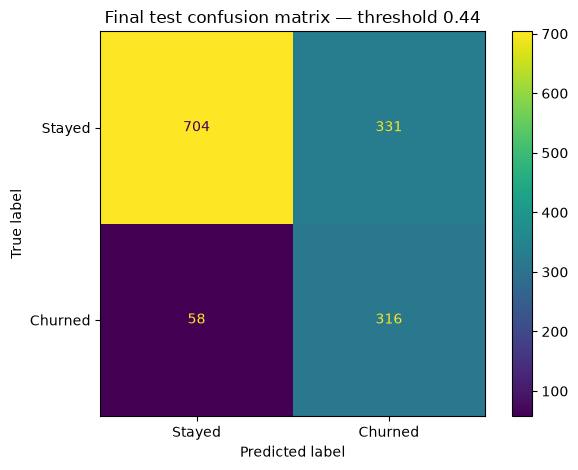

              precision    recall  f1-score   support

      Stayed       0.92      0.68      0.78      1035
     Churned       0.49      0.84      0.62       374

    accuracy                           0.72      1409
   macro avg       0.71      0.76      0.70      1409
weighted avg       0.81      0.72      0.74      1409



In [17]:
# refit using all non-test data. The validation-selected threshold is retained.
final_model = clone(selected_candidate)
final_model.fit(X_train_full, y_train_full)

# predict churn probabilities on the test set.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int) # convert probabilities into class predictions using the selected threshold.

# evaluate the final model on the unseen test set.
final_test_metrics = evaluate_probabilities(y_test, test_probabilities, threshold=selected_threshold)
final_test_metrics_df = pd.DataFrame([final_test_metrics], index=[selected_model_name])
display(final_test_metrics_df.round(3))

# create and visualize the confusion matrix.
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stayed", "Churned"]).plot(values_format="d")
plt.title(f"Final test confusion matrix — threshold {selected_threshold:.2f}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, test_predictions, target_names=["Stayed", "Churned"], zero_division=0))


On the test set at the 0.44 threshold, Tuned CatBoost achieved a Recall of 84.5% (0.84), Precision of 48.8% (0.49), F1-score of 0.62, Accuracy of 0.72, ROC-AUC of 0.85, and PR-AUC of 0.67. The confusion matrix shows that the model correctly identified 316 out of 374 customers who churned and 704 out of 1,035 customers who stayed, while 58 churners were missed and 331 customers who stayed were incorrectly flagged as likely to churn.


## 12- Review the final test errors

This section summarizes how many churners were detected and how many were missed. False negatives are customers who churned but were not flagged, and false positives are customers flagged as likely to churn who actually stayed. Reviewing these counts helps interpret Recall and Precision in practical terms.

In [18]:
# create error summary 
tn, fp, fn, tp = cm.ravel()
error_summary = pd.DataFrame({"Measure": ["True negatives", "False positives", "False negatives", "True positives"],
                             "Count": [tn, fp, fn, tp]})
display(error_summary)
print(f"Test recall: {recall_score(y_test, test_predictions, zero_division=0):.3f}")
print(f"Test precision: {precision_score(y_test, test_predictions, zero_division=0):.3f}")

,Measure,Count
0,True negatives,704
1,False positives,331
2,False negatives,58
3,True positives,316


Test recall: 0.845
Test precision: 0.488


## 13- Feature importance on an independent holdout

Permutation importance using ROC-AUC is computed on a separate holdout set that was not used to train the model, select the candidate, or choose the threshold. This avoids reusing the validation set for feature importance and keeps the test set reserved for the final performance estimate.

In [19]:
from sklearn.inspection import permutation_importance

# Fit a copy of the selected candidate on training data only.
importance_model = clone(selected_candidate)
importance_model.fit(X_train, y_train)

perm = permutation_importance(
    importance_model, X_importance, y_importance,
    scoring="roc_auc", n_repeats=15,
    random_state=RANDOM_STATE, n_jobs=-1)

importance_df = pd.DataFrame({
    "feature": X_importance.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(15).round(4))

,feature,importance_mean,importance_std
14,Contract,0.05,0.01
4,tenure,0.03,0.01
17,MonthlyCharges,0.01,0.01
18,TotalCharges,0.01,0.01
7,InternetService,0.01,0.00
16,PaymentMethod,0.01,0.00
15,PaperlessBilling,0.01,0.00
8,OnlineSecurity,0.01,0.00
6,MultipleLines,0.00,0.00
11,TechSupport,0.00,0.00


The permutation importance analysis shows that Contract is the most influential feature in the model (0.05), followed by tenure (0.03), with smaller contributions from MonthlyCharges, TotalCharges, InternetService, PaymentMethod, PaperlessBilling, and OnlineSecurity (0.01 each). This indicates that contract type, customer tenure, billing structure, and internet service play the main roles in predicting churn, while the remaining features have near-zero individual impact on ROC-AUC.


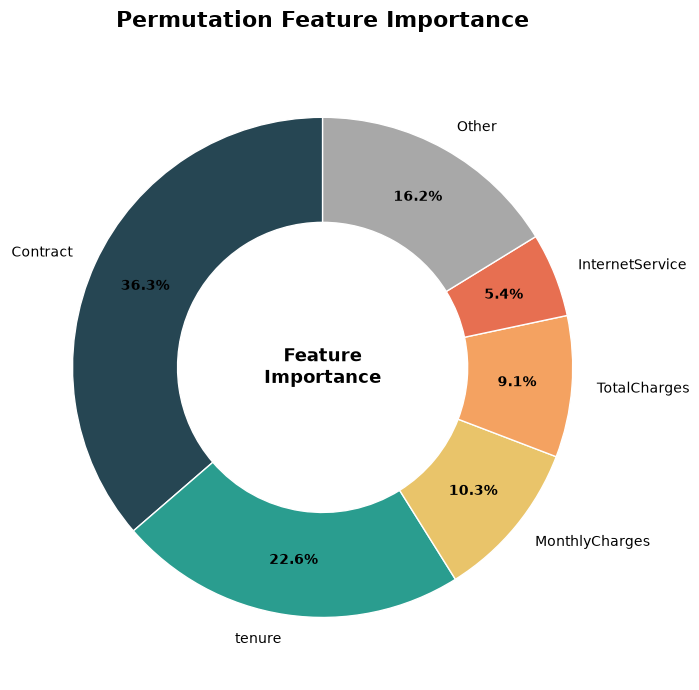

In [ ]:
# Sort and select top 5 features
plot_df = importance_df.sort_values(
    "importance_mean", ascending=False).copy()

plot_df["importance_mean"] = plot_df["importance_mean"].clip(lower=0)

top5 = plot_df.head(5).copy()

# Combine remaining features into Other
other_importance = max(0.0, float(plot_df.iloc[5:]["importance_mean"].sum()))

pie_df = top5[["feature", "importance_mean"]].copy()

pie_df.loc[len(pie_df)] = ["Other", other_importance]

# Donut chart
fig, ax = plt.subplots(figsize=(9, 7))

colors = [
    "#264653",
    "#2A9D8F",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#A8A8A8"]

wedges, texts, autotexts = ax.pie(
    pie_df["importance_mean"],
    labels=pie_df["feature"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor="white"))

plt.setp(autotexts, fontsize=10, fontweight="bold")

ax.text(
    0, 0,
    "Feature\nImportance",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold")

ax.set_title(
    "Permutation Feature Importance",
    fontsize=16,
    fontweight="bold",
    pad=20)

plt.tight_layout()
plt.show()


## 14- Save the fitted model

Save the complete fitted preprocessing and model pipeline, the selected threshold, feature names, and target mapping in one artifact, and save a JSON metadata file with the selection criteria and final test metrics.

In [21]:
artifact = {
    "model": final_model,
    "threshold": float(selected_threshold),
    "features": list(X_train_full.columns),
    "primary_metric": "Recall",
    "target_mapping": {"No": 0, "Yes": 1},
    "model_name": selected_model_name,
    "random_state": RANDOM_STATE}

joblib.dump(artifact, ARTIFACT_PATH)

metadata = {
    "model_name": selected_model_name,
    "threshold": float(selected_threshold),
    "features": list(X_train_full.columns),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target_mapping": {"No": 0, "Yes": 1},
    "random_state": RANDOM_STATE,
    "project_priority_metric": "Recall",
    "final_selection_metric": "Recall",
    "threshold_selection_metric": "Precision (Recall >= 0.80)",
    "test_metrics": {key: float(value) for key, value in final_test_metrics.items()}}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print(f"Saved model artifact: {Path(ARTIFACT_PATH).resolve()}")
print(f"Saved model metadata: {Path(METADATA_PATH).resolve()}")
print(f"Model: {selected_model_name} | Threshold: {selected_threshold:.2f}")


Saved model artifact: E:\depi\final project\churn_model.pkl
Saved model metadata: E:\depi\final project\churn_model_metadata.json
Model: Tuned CatBoost | Threshold: 0.44
